# 2026 DL Lab4: Semantic Segmentation on CIHP

Before we start, please put **your name** and **SID** in following format: <br>
Hi I'm 陸仁賈, 314831000.

**Your Answer:**    
Hi I'm 王薪愷, 315832002.

## Overview

- Semantic segmentation assigns a semantic class to every pixel in an image.
- In this assignment, predict **20 CIHP classes**: background, clothing and human body parts.
- Implement the original **U-Net from scratch**, using RGB images and semantic category masks.
- Images and masks are already prepared at **320 x 320**, preserving aspect ratio.
  Mask value **255** is an ignored pixel, including padded borders; it is not a 21st class.
- Complete the marked exercises: augmentation, U-Net, pixel accuracy, mIoU, Dice loss and training.
  See `ASSIGNMENT_README.md` and `DATASET_README.md` for the course protocol.

## Kaggle Competition

The TA will announce the **2026 competition link and grading thresholds** separately.
Use the course test images and export `output.csv` with columns `index,pred_mask`.
The reference course score is the mean of per-image mIoU values, including background,
and excluding pixels whose ground-truth value is 255. It is not the official CIHP benchmark score.
Train from scratch using the supplied training set; use validation data for model selection.

## Unzip Data

Place this notebook beside the prepared `data/` folder. Data are already prepared on the TA's machine.

- `data/train/`: 28,280 RGB training PNGs
- `data/train_mask/`: corresponding semantic masks
- `data/val/`: 1,000 RGB validation PNGs
- `data/val_mask/`: corresponding semantic masks
- `data/test/`: 3,961 RGB course-test PNGs
- `data/test_index.csv`: fixed mapping between submission index and test filename

Each image/mask is 320 x 320. Masks contain class IDs 0--19 and ignore value 255.
Test answers are kept by the TA. This course test split comes from labeled official validation data;
the official unlabeled CIHP test split is not used here.

# Import Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import torchvision
import torch.nn.functional as F
from torch.autograd import Variable

from PIL import Image
import cv2
import albumentations as A

import time
import os
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from pathlib import Path
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Preprocessing

#### Verify that the paths to the image and mask are correct, and plot the position of the mask on the image.

First, the code establishes DataFrames for the paths of training and validation images, including their corresponding mask paths.

Second, it presents the total number of images in both the training and validation sets.

Third, the code loads a sample training image and its associated mask, visually demonstrating the image and the applied mask in a graphical representation.

In [5]:
# Override this path when running from a different location or after moving the data.
DATA_ROOT = Path("./dataset")
if (Path.cwd() / "data/train").is_dir():
    DATA_ROOT = Path.cwd() / "data"
elif (Path.cwd() / "CIHP/data/train").is_dir():
    DATA_ROOT = Path.cwd() / "CIHP/data"
DATA_ROOT = DATA_ROOT.resolve()
for folder in ["train", "train_mask", "val", "val_mask", "test"]:
    if not (DATA_ROOT / folder).is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to the prepared CIHP data folder: {DATA_ROOT / folder}")

TRAIN_IMAGE_PATH = str(DATA_ROOT / "train") + os.sep
VAL_IMAGE_PATH = str(DATA_ROOT / "val") + os.sep
TRAIN_MASK_PATH = str(DATA_ROOT / "train_mask") + os.sep
VAL_MASK_PATH = str(DATA_ROOT / "val_mask") + os.sep
OUTPUT_DIR = DATA_ROOT.parent / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset:", DATA_ROOT)

Dataset: /root/DL/HW4/dataset


In [6]:
n_classes = 20
IGNORE_INDEX = 255
IMAGE_SIZE = 320
CLASS_NAMES = ['Background', 'Hat', 'Hair', 'Glove', 'Sunglasses', 'Upper-clothes', 'Dress', 'Coat', 'Socks', 'Pants', 'Torso-skin', 'Scarf', 'Skirt', 'Face', 'Left-arm', 'Right-arm', 'Left-leg', 'Right-leg', 'Left-shoe', 'Right-shoe']

def create_df(IMAGE_PATH):
    name = sorted(path.stem for path in Path(IMAGE_PATH).glob("*.png"))
    if not name:
        raise FileNotFoundError(f"No prepared PNG images in {IMAGE_PATH}")
    return pd.DataFrame({'id': name}, index=np.arange(len(name)))

train_df = create_df(TRAIN_IMAGE_PATH)
val_df = create_df(VAL_IMAGE_PATH)
print('Total Train Images: ', len(train_df))
print('Total Val Images: ', len(val_df))

Total Train Images:  28280
Total Val Images:  1000


In [7]:
X_train = train_df['id'].to_numpy()
X_val = val_df['id'].to_numpy()

Image Size (320, 320, 3)
Mask Size (320, 320)


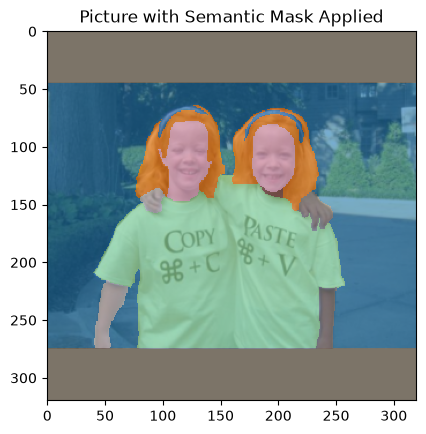

In [8]:
img = Image.open(TRAIN_IMAGE_PATH + train_df['id'][100] + '.png')
mask = np.asarray(Image.open(TRAIN_MASK_PATH + train_df['id'][100] + '.png'))
print('Image Size', np.asarray(img).shape)
print('Mask Size', mask.shape)
plt.imshow(img)
plt.imshow(np.ma.masked_equal(mask, IGNORE_INDEX), alpha=0.6,
           cmap='tab20', vmin=0, vmax=n_classes - 1, interpolation='nearest')
plt.title('Picture with Semantic Mask Applied')
plt.show()

# Loading the Dataset

Define the CIHPDataset for loading the dataset, where each sample comprises an image and its corresponding mask

Build a classs inherit `torch.utils.data.Dataset`.

Implement `__init__`, `__getitem__` and `__len__` 3 functions.  

Some operations could be there: setting location of dataset, the method of reading data, label of dataset or transform of dataset.

See [torch.utils.data.Dataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) for more details

The dataset includes a provided, label-aware horizontal flip. It swaps class IDs
14/15, 16/17 and 18/19 after mirroring. Do not add a plain `HorizontalFlip` to the
augmentation pipeline, or the anatomical labels will become inconsistent.

In [9]:
class CIHPDataset(Dataset):

    def __init__(self, img_path, mask_path, X, mean, std, transform=None, hflip_prob=0.0):
        self.img_path = img_path
        self.mask_path = mask_path
        self.X = X
        self.transform = transform
        self.mean = mean
        self.std = std
        self.hflip_prob = hflip_prob
        # Simultaneous lookup avoids overwriting one side before swapping the other.
        self.flip_lut = np.arange(256, dtype=np.uint8)
        self.flip_lut[[14, 15, 16, 17, 18, 19]] = [15, 14, 17, 16, 19, 18]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        with Image.open(self.img_path + self.X[idx] + '.png') as handle:
            img = np.array(handle.convert('RGB'))
        with Image.open(self.mask_path + self.X[idx] + '.png') as handle:
            mask = np.array(handle, dtype=np.uint8)

        if random.random() < self.hflip_prob:
            img = np.ascontiguousarray(img[:, ::-1])
            mask = np.ascontiguousarray(self.flip_lut[mask[:, ::-1]])

        if self.transform is not None:
            aug = self.transform(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']

        t = T.Compose([T.ToTensor(), T.Normalize(self.mean, self.std)])
        img = t(Image.fromarray(img))
        mask = torch.from_numpy(np.ascontiguousarray(mask)).long()
        return img, mask

## Data augmentation

Use `albumentations.Compose` to transform each image and its mask together.
Photometric operations such as brightness/contrast changes affect only RGB images.
The Dataset already normalizes the image and provides correct horizontal flipping for training.
Do not add `HorizontalFlip`, `Normalize` or `ToTensorV2` here.
If adding spatial transforms, use nearest-neighbor interpolation for masks and fill new mask
pixels with 255; keep output size 320 x 320 and at least one valid pixel per sample.
Validation and test preprocessing must be deterministic; `A.Compose([])` is sufficient.

In [21]:
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]

# For TRAIN
########################################################################
#  TODO: use albumentations for paired image/mask augmentation        #
#  This one is for training, find the composition to get better result #
########################################################################
transforms_train = A.Compose([
    A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE, interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussianBlur(blur_limit=(3, 5), p=0.15),
    
])
########################################################################
#                           End of your code                           #
########################################################################


# For VAL
########################################################################
#  For validation/test we avoid strong augmentations that change labels #
########################################################################
transforms_val = A.Compose([
    A.Resize(height=IMAGE_SIZE, width=IMAGE_SIZE, interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST),
])
########################################################################
#                           End of your code                           #
########################################################################


#datasets
train_set = CIHPDataset(TRAIN_IMAGE_PATH, TRAIN_MASK_PATH, X_train, mean, std, transforms_train, hflip_prob=0.5)
val_set = CIHPDataset(VAL_IMAGE_PATH, VAL_MASK_PATH, X_val, mean, std, transforms_val)

#dataloader
batch_size= 16

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1, shuffle=False)

In [22]:
train_set[0]

(tensor([[[-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458],
          [-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458],
          [-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458],
          ...,
          [-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458],
          [-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458],
          [-0.0458, -0.0458, -0.0458,  ..., -0.0458, -0.0458, -0.0458]],
 
         [[-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399],
          [-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399],
          [-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399],
          ...,
          [-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399],
          [-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399],
          [-0.0399, -0.0399, -0.0399,  ..., -0.0399, -0.0399, -0.0399]],
 
         [[-0.0092, -0.0092, -0.0092,  ..., -0.0092, -0.0092, -0.0092],
          [-0.0092, -0.0092,

# U-net

U-net is a fully convolution neural network for image semantic segmentation. Consist of encoder and decoder parts connected with skip connections. Encoder extract features of different spatial resolution (skip connections) which are used by decoder to define accurate segmentation mask. Use concatenation for fusing decoder blocks with skip connections.


![image](https://hackmd.io/_uploads/rJXtsY_Up.png)

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """
    Block with two convolutional blocks
    """

    def __init__(self, in_channels, out_channels, mid_channels=None):
        """
        Double convolution

        :param in_channels: number of in channels for first conv layer
        :param out_channels: number of out channels for last conv layer
        :param mid_channels: number of out channels for first conv layer
        """
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        ########################################################################
        #  TODO:                                                               #
        #  write model that contains 2 conv layer with batch normalization     #
        #  and relu activation function                                        #
        ########################################################################

        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        ########################################################################
        #                           End of your code                           #
        ########################################################################

    def forward(self, x):
        return self.double_conv(x)


class Down(nn.Module):
    """
    Block for down path
    """

    def __init__(self, in_channels, out_channels):
        """
        Down block

        :param in_channels: number of in channels for double conv block
        :param out_channels: number of out channels for double conv block
        """
        super().__init__()
        ########################################################################
        #  TODO:                                                               #
        #  write model which contains pooling and double conv block            #
        ########################################################################
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),
            DoubleConv(in_channels, out_channels),
        )
        ########################################################################
        #                           End of your code                           #
        ########################################################################

    def forward(self, x):
        return self.maxpool_conv(x)


class Up(nn.Module):
    """
    Block for up path
    """

    def __init__(self, in_channels, out_channels):
        """
        Down block

        :param in_channels: number of in channels for transpose convolution
        :param out_channels: number of out channels for double conv block
        """
        super().__init__()

        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):

        #########################################################################################
        # TODO:                                                                                 #
        # 1. Up-sample the input tensor using transpose convolution                             #
        # 2. Calculate the difference in height and width between x2 and the up-sampled x1      #
        # 3. Pad the up-sampled x1 to match the size of x2                                      #
        # 4. Concatenate x2 and the up-sampled x1 along the channel dimension                   #
        #########################################################################################
        x1 = self.up(x1)
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        x = torch.cat([x2, x1], dim=1)
        #########################################################################################
        #                           End of your code                                            #
        #########################################################################################


        return self.conv(x)

class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        """
        Final convolution block

        :param in_channels: number of in channels for conv layer
        :param out_channels: number of out channels for conv layer
        """
        super(OutConv, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)

In [24]:
class UNet(nn.Module):
    """UNet model"""
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes

        #############################################################
        #  implement the model according to the UNet architecture   #
        #############################################################
        self.inc = DoubleConv(n_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return logits
        #############################################################
        #                   End of your code                        #
        #############################################################

In [25]:
model = UNet(n_channels=3, n_classes=n_classes)

In [26]:
model

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
 

# Training

In this section, you will implement some functions in your training loop. There are several crucial functions you need to implement:

- Pixel Accuracy: Pixel Accuracy measures the percentage of correctly predicted pixels out of the total pixels in the image

- mIoU (Mean Intersection over Union): mIoU evaluates the spatial overlap between the predicted and ground truth segmentation masks for multiple classes.

- Dice Loss: Dice Loss quantifies the dissimilarity between the predicted and ground truth masks, emphasizing the agreement between the two masks

Try to use labeled data design and train a segmentor (Unet) from scratch to predict the mask of a multi-person CIHP image.

Exclude all target pixels with value 255 from both losses and metrics.
Keep background (class 0) in the metric. The displayed training mIoU is averaged per batch;
validation uses batch size 1, so its mIoU equals the course's mean per-image mIoU protocol.

In [27]:
def pixel_accuracy(output, mask, ignore_index=IGNORE_INDEX):
    with torch.no_grad():
        valid = mask != ignore_index
        if not valid.any():
            return 0.0
        #############################################################################################################
        # TODO: argmax over classes; compute accuracy only at valid pixels.                                         #
        #############################################################################################################
        pred = output.argmax(dim=1)
        correct = (pred == mask) & valid
        accuracy = (correct.sum().float() / valid.sum()).item()
        #############################################################################################################
        #                                      End of your code                                                     #
        #############################################################################################################
    return accuracy

## mIoU

mean Intersection over Union (mIoU), a metric used to evaluate the performance of a segmentation model. It takes predicted masks and ground truth masks as input, computes the IoU for each class, and returns the average IoU across all classes.

![image](https://hackmd.io/_uploads/SkLIbhFL6.png)

Course protocol: ignore ground-truth pixels with value 255. Include classes 0--19.
For each image, average IoU over classes with nonzero union, then average across images.
A false-positive class with no ground-truth pixels still has nonzero union and must count as IoU=0.

In [28]:
def mIoU(pred_mask, mask, smooth=1e-10, n_classes=20, ignore_idx=IGNORE_INDEX):
    """Batch mIoU; with batch size 1 this is the course per-image score."""
    with torch.no_grad():
        preds = pred_mask.argmax(dim=1).reshape(-1)
        mask = mask.reshape(-1)
        valid = mask != ignore_idx
        preds, mask = preds[valid], mask[valid]
        ious = []
        for cls in range(n_classes):
            pred_c = preds == cls
            label_c = mask == cls
            #############################################################################################################
            # TODO: Calculate the intersection and union for the current class.                                         #
            #############################################################################################################
            intersect = (pred_c & label_c).sum().float()
            union = (pred_c | label_c).sum().float()
            #############################################################################################################
            #                                      End of your code                                                     #
            #############################################################################################################
            if union.item() == 0:
                continue
            ious.append((intersect + smooth) / (union + smooth))
        return float(torch.stack(ious).mean().item()) if ious else 0.0

## Dice Loss

Dice loss is based on Sørensen-Dice coefficient. It measures the overlap between the predicted and target segmentation masks. Dice loss provides a differentiable and smooth measure of segmentation accuracy.

${DiceLoss}(y, \bar p) = 1 - \cfrac{(2y\bar p + \epsilon)}{(y + \bar p + \epsilon)}$

- $y$ represents the ground truth mask.
- $\bar p$ represents the predicted mask.
- $\epsilon$ is a small constant added for numerical stability.

Apply softmax over classes. Replace ignored target IDs before one-hot encoding, then mask out
ignored positions in both predictions and targets. Sum over batch and spatial dimensions,
and average Dice across all 20 classes, including background. An entirely ignored batch returns zero loss.

In [29]:
class DiceLoss(nn.Module):
    """Multiclass soft Dice loss, with ignored pixels excluded."""

    def __init__(self, ignore_index=IGNORE_INDEX):
        super().__init__()
        self.ignore_index = ignore_index

    def forward(self, inputs, targets, eps=1e-6):
        # inputs: (B, C, H, W); targets: (B, H, W), class IDs or 255.
        #######################################
        # TODO: implement masked soft Dice loss.
        #######################################
        n_classes = inputs.size(1)
        
        probs = F.softmax(inputs, dim=1)
        
        valid = targets != self.ignore_index
        safe_targets = targets.clone()
        safe_targets[~valid] = 0
        
        one_hot = F.one_hot(safe_targets.long(), num_classes=n_classes).permute(0, 3, 1, 2).to(probs.dtype)
        
        valid = valid.unsqueeze(1).to(probs.dtype)
        probs = probs * valid
        one_hot = one_hot * valid
        
        dims = (0, 2, 3)
        intersection = (probs * one_hot).sum(dim=dims)
        denominator = probs.sum(dim=dims) + one_hot.sum(dim=dims)
        
        dice = (2.0 * intersection + eps) / (denominator + eps)
        #######################################
        #          End of your code           #
        #######################################
        return 1.0 - dice.mean()

# Training loop

Call train function in a loop.  
Take a break and wait.

In [30]:
def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit(epochs, model, train_loader, val_loader, criterion1, criterion2, optimizer, scheduler, patch=False):
    torch.cuda.empty_cache()
    train_losses = []
    test_losses = []
    val_iou = []; val_acc = []
    train_iou = []; train_acc = []
    lrs = []
    min_loss = np.inf
    not_improve = 0

    model.to(device)
    fit_time = time.time()
    for e in range(epochs):
        since = time.time()
        running_loss = 0
        iou_score = 0
        accuracy = 0
        #training loop
        model.train()
        for i, data in enumerate(tqdm(train_loader, desc=f"Train {e+1}/{epochs}")):
            #training phase
            ########################################################################
            # TODO: Forward, backward and optimize                                 #
            # 1. process input through the network                                 #
            # 2. compute the two losses                                            #
            # 3. calculate mIoU and pixel accuracy                                   #
            # 4. propagate gradients back into the network’s parameters            #
            # 5. update the weights of the network                                 #
            # 6. reset gradient                                                    #
            ########################################################################
            image, mask = data

            # Also implement zero_grad(), backward() and optimizer.step() in this block.
            image = image.to(device)
            mask = mask.to(device)
            
            optimizer.zero_grad()
            
            output = model(image)
            loss = criterion1(output, mask) + criterion2(output, mask)
            iou_score += mIoU(output, mask)
            accuracy += pixel_accuracy(output, mask)
            
            loss.backward()
            optimizer.step()
            ########################################################################
            #                           End of your code                           #
            ########################################################################
            #step the learning rate
            lrs.append(get_lr(optimizer))
            scheduler.step()

            running_loss += loss.item()

        else:
            model.eval()
            test_loss = 0
            test_accuracy = 0
            val_iou_score = 0
            #validation loop
            with torch.no_grad():
                for i, data in enumerate(tqdm(val_loader, desc=f"Val {e+1}/{epochs}")):
                    ########################################################################
                    # TODO: Forward pass and validation metrics                           #
                    # 1. process input through the network                                 #
                    # 2. compute the two losses                                            #
                    # 3. calculate mIoU and pixel accuracy                                   #
                    # 4. save this batch's loss into test_loss                             #
                    ########################################################################
                    image, mask = data

                    image = image.to(device)
                    mask = mask.to(device)
                    
                    output = model(image)
                    
                    val_iou_score += mIoU(output, mask)
                    test_accuracy += pixel_accuracy(output, mask)
                    loss = criterion1(output, mask) + criterion2(output, mask)
                    test_loss += loss.item()
                    ########################################################################
                    #                           End of your code                           #
                    ########################################################################

            #calculatio mean for each batch
            train_losses.append(running_loss/len(train_loader))
            test_losses.append(test_loss/len(val_loader))


            if (test_loss / len(val_loader)) < min_loss:
                print('Loss Decreasing.. {:.3f} >> {:.3f}'.format(min_loss, test_loss / len(val_loader)))
                min_loss = test_loss / len(val_loader)
                not_improve = 0
                torch.save(model.state_dict(), OUTPUT_DIR / 'Unet-CIHP-best.pt')
            else:
                not_improve += 1
                print(f'Loss Not Decrease for {not_improve} time')

            #iou
            val_iou.append(val_iou_score/len(val_loader))
            train_iou.append(iou_score/len(train_loader))
            train_acc.append(accuracy/len(train_loader))
            val_acc.append(test_accuracy/ len(val_loader))
            print("Epoch:{}/{}..".format(e+1, epochs),
                  "Train Loss: {:.3f}..".format(running_loss/len(train_loader)),
                  "Val Loss: {:.3f}..".format(test_loss/len(val_loader)),
                  "Train mIoU:{:.3f}..".format(iou_score/len(train_loader)),
                  "Val mIoU: {:.3f}..".format(val_iou_score/len(val_loader)),
                  "Train Acc:{:.3f}..".format(accuracy/len(train_loader)),
                  "Val Acc:{:.3f}..".format(test_accuracy/len(val_loader)),
                  "Time: {:.2f}m".format((time.time()-since)/60))

            if not_improve >= 7:
                print('Loss not decrease for 7 epochs, Stop Training')
                break

    history = {'train_loss' : train_losses, 'val_loss': test_losses,
               'train_miou' :train_iou, 'val_miou':val_iou,
               'train_acc' :train_acc, 'val_acc':val_acc,
               'lrs': lrs}
    print('Total time: {:.2f} m' .format((time.time()- fit_time)/60))
    return history

In [31]:
################################################################################
#     You can adjust those hyper parameters to loop for max_epochs times       #
################################################################################
max_lr = 1e-3
epoch = 30
weight_decay = 1e-4

criterion1 = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
criterion2 = DiceLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=weight_decay)
sched = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr, epochs=epoch, steps_per_epoch=len(train_loader))

history = fit(epoch, model, train_loader, val_loader, criterion1, criterion2, optimizer, sched)
################################################################################
#                               End of your code                               #
################################################################################

Val 1/30: 100%|██████████| 1000/1000 [00:27<00:00, 36.81it/s]


Loss Decreasing.. inf >> 1.674
Epoch:1/30.. Train Loss: 2.265.. Val Loss: 1.674.. Train mIoU:0.132.. Val mIoU: 0.271.. Train Acc:0.658.. Val Acc:0.749.. Time: 18.12m


Val 2/30: 100%|██████████| 1000/1000 [00:21<00:00, 47.05it/s]


Loss Decreasing.. 1.674 >> 1.467
Epoch:2/30.. Train Loss: 1.507.. Val Loss: 1.467.. Train mIoU:0.248.. Val mIoU: 0.340.. Train Acc:0.759.. Val Acc:0.789.. Time: 15.47m


Val 3/30: 100%|██████████| 1000/1000 [00:21<00:00, 47.52it/s]


...

Loss Not Decrease for 5 time
Epoch:23/30.. Train Loss: 0.535.. Val Loss: 1.154.. Train mIoU:0.643.. Val mIoU: 0.513.. Train Acc:0.928.. Val Acc:0.873.. Time: 16.72m


Val 24/30: 100%|██████████| 1000/1000 [00:22<00:00, 43.94it/s]


Loss Not Decrease for 6 time
Epoch:24/30.. Train Loss: 0.514.. Val Loss: 1.157.. Train mIoU:0.656.. Val mIoU: 0.512.. Train Acc:0.932.. Val Acc:0.874.. Time: 15.59m


Val 25/30: 100%|██████████| 1000/1000 [00:22<00:00, 44.64it/s]

Loss Not Decrease for 7 time
Epoch:25/30.. Train Loss: 0.494.. Val Loss: 1.163.. Train mIoU:0.667.. Val mIoU: 0.515.. Train Acc:0.935.. Val Acc:0.875.. Time: 15.62m
Loss not decrease for 7 epochs, Stop Training
Total time: 393.65 m


In [32]:
torch.save(model.state_dict(), OUTPUT_DIR / 'Unet-CIHP-last.pt')

#### Visualize accuracy and loss

In [33]:
def plot_loss(history):
    plt.plot(history['val_loss'], label='val', marker='o')
    plt.plot( history['train_loss'], label='train', marker='o')
    plt.title('Loss per epoch'); plt.ylabel('loss');
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

def plot_score(history):
    plt.plot(history['train_miou'], label='train_mIoU', marker='*')
    plt.plot(history['val_miou'], label='val_mIoU',  marker='*')
    plt.title('Score per epoch'); plt.ylabel('mean IoU')
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

def plot_acc(history):
    plt.plot(history['train_acc'], label='train_accuracy', marker='*')
    plt.plot(history['val_acc'], label='val_accuracy',  marker='*')
    plt.title('Accuracy per epoch'); plt.ylabel('Accuracy')
    plt.xlabel('epoch')
    plt.legend(), plt.grid()
    plt.show()

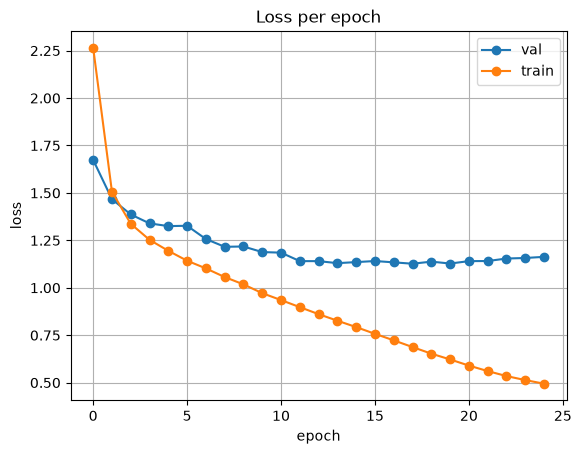

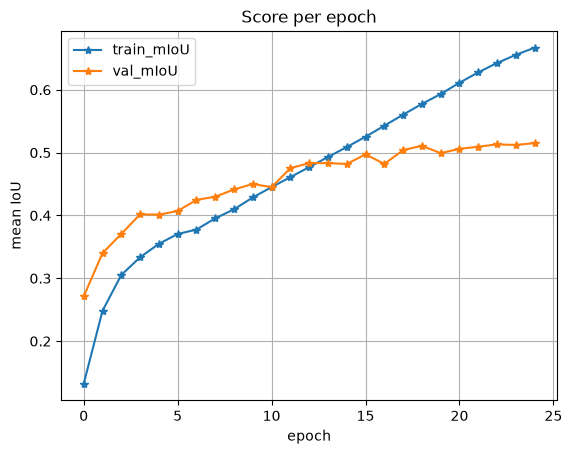

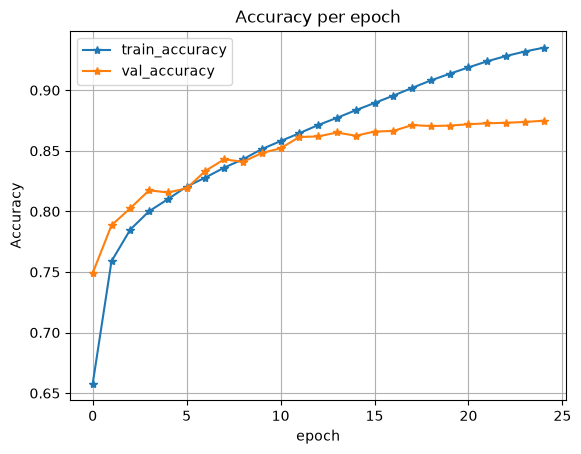

In [34]:
plot_loss(history)
plot_score(history)
plot_acc(history)

### Predict Result

Load the best validation-loss checkpoint and predict the **course test set**.
Export `outputs/output.csv` with columns `index,pred_mask`.
Each `pred_mask` is a JSON-compatible nested 320 x 320 list of integers 0--19.
Predict a class at every pixel; the grader ignores pixels using its ground-truth mask.
Row indices must follow `data/test_index.csv`, starting at 0.

The 2026 Kaggle link and public/private split will be announced by the TA.
Do not reuse the 2025 competition link. Run the training section before inference;
this package intentionally contains no trained checkpoint.

In [35]:
TEST_IMAGE_PATH = str(DATA_ROOT / 'test') + os.sep

In [36]:
test_df = create_df(TEST_IMAGE_PATH)
test_index = pd.read_csv(DATA_ROOT / 'test_index.csv')
assert test_index['index'].tolist() == list(range(len(test_df)))
assert test_index['filename'].tolist() == (test_df['id'] + '.png').tolist()

In [37]:
X_test = test_df['id'].to_numpy()

In [38]:
checkpoint = OUTPUT_DIR / 'Unet-CIHP-best.pt'
if not checkpoint.is_file():
    raise FileNotFoundError('Run training first to create outputs/Unet-CIHP-best.pt')
model = UNet(n_channels=3, n_classes=n_classes)
model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
model = model.to(device)

In [39]:
class CIHPTestDataset(Dataset):
    def __init__(self, img_path, X, transform=None):
        self.img_path = img_path
        self.X = X
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        with Image.open(self.img_path + self.X[idx] + '.png') as handle:
            img = np.array(handle.convert('RGB'))
        if self.transform is not None:
            img = self.transform(image=img)['image']
        return Image.fromarray(img)

test_set = CIHPTestDataset(TEST_IMAGE_PATH, X_test)
print(len(test_set))

3961


In [40]:
def predict_image(model, image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    model.eval()
    t = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
    image = t(image)
    model.to(device); image=image.to(device)
    with torch.no_grad():

        image = image.unsqueeze(0)

        output = model(image)
        masked = torch.argmax(output, dim=1)
        masked = masked.cpu().squeeze(0)
    return masked

In [41]:
import csv
import json

output_path = OUTPUT_DIR / 'output.csv'
with output_path.open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=['index', 'pred_mask'])
    writer.writeheader()
    for i in tqdm(range(len(test_set)), desc='Predict'):
        pred_mask = predict_image(model, test_set[i])
        writer.writerow({'index': i, 'pred_mask': json.dumps(pred_mask.tolist(), separators=(',', ':'))})
print('Saved:', output_path)

Predict: 100%|██████████| 3961/3961 [02:36<00:00, 25.30it/s]

Saved: /root/DL/HW4/outputs/output.csv
